# Probabilistic Learning — Sleep Stage Analysis
## NB 1/6 · Dataset · Balancing · Random Variables · Markov Chains

**Dataset:** Sleep-EDF Cassette (Physionet, 25 subjects, 46 688 epochs)  
**Features:** 6-channel Welch PSD → 126-dim random vector → 30-dim PCA

---
### References
[1] Kemp B. et al. (2000) *IEEE Trans. Biomed. Eng.* **47**(9). doi:10.13026/C2X31R  
[2] Berry R. et al. (2012) *AASM Manual for Scoring Sleep, v2.4*  
[3] Welch P.D. (1967) Power spectrum estimation. *IEEE Trans. Audio* **15**(2)  
[4] Hotelling H. (1933) Analysis of a complex of variables. *J. Educ. Psychol.* **24**(6)  
[5] Norris J.R. (1997) *Markov Chains.* Cambridge University Press (237 pp.)  
[6] Yang C.M. et al. (2011) Sleep-stage transitions. *Sleep* **34**(10)  
[7] He H. & Garcia E. (2009) Learning from imbalanced data. *IEEE TKDE* **21**(9)

In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import linalg
from scipy.linalg import expm
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':11})
STAGE_NAMES = ['W','N1','N2','N3','REM']; N_STAGES = 5
STAGE_COLORS = {'W':'#4c78a8','N1':'#f58518','N2':'#54a24b',
                'N3':'#e45756','REM':'#b279a2'}
print('Imports OK')

Imports OK


## §1 — Data Loading

We load EDF recordings directly through MNE [1], avoiding any CSV intermediary. Each 30-second epoch is annotated with one of five AASM stages [2].

In [19]:
from shared_data import (
    load_all_subjects, build_train_test, print_metrics,
    STAGE_NAMES, N_STAGES, STAGE_MAP, BANDS, CAP_RATIO
)

print('Loading Sleep-EDF (25 subjects) from MNE EDF files...')
rows = load_all_subjects(subjects=range(25), recordings=(1,))
total = sum(r['n_epochs'] for r in rows)
print(f'Loaded {len(rows)} subjects, {total:,} total epochs')

Loading Sleep-EDF (25 subjects) from MNE EDF files...
  subj  0: 1802 epochs, 6 ch
  subj  1: 1761 epochs, 6 ch
  subj  2: 1694 epochs, 6 ch
  subj  3: 1763 epochs, 6 ch
  subj  4: 1987 epochs, 6 ch
  subj  5: 1901 epochs, 6 ch
  subj  6: 1718 epochs, 6 ch
  subj  7: 1849 epochs, 6 ch
  subj  8: 1877 epochs, 6 ch
  subj  9: 1877 epochs, 6 ch
  subj 10: 1806 epochs, 6 ch
  subj 11: 1803 epochs, 6 ch
  subj 12: 1954 epochs, 6 ch
  subj 13: 1930 epochs, 6 ch
  subj 14: 1782 epochs, 6 ch
  subj 15: 1786 epochs, 6 ch
  subj 16: 1827 epochs, 6 ch
  subj 17: 1909 epochs, 6 ch
  subj 18: 1800 epochs, 6 ch
  subj 19: 2649 epochs, 6 ch
  subj 20: 1807 epochs, 6 ch
  subj 21: 1782 epochs, 6 ch
  subj 22: 1865 epochs, 6 ch
  subj 23: 1901 epochs, 6 ch
  subj 24: 1858 epochs, 6 ch
Loaded 25 subjects, 46,688 total epochs


In [20]:
r0 = rows[0]
print(f'Subject 0: {r0["n_epochs"]} epochs')
print(f'Feature vector: {r0["X"].shape}  ->  (n_epochs, 126-dim random vector)')
df_s = pd.DataFrame(r0['X'][:4, :8], columns=[f'feat_{i}' for i in range(8)])
df_s.insert(0, 'stage', [STAGE_NAMES[s] for s in r0['y'][:4]])
print('\nFirst 4 epochs, first 8 features (sample of random vector):')
print(df_s.to_string())

Subject 0: 1802 epochs
Feature vector: (1802, 126)  ->  (n_epochs, 126-dim random vector)

First 4 epochs, first 8 features (sample of random vector):
  stage        feat_0    feat_1    feat_2    feat_3        feat_4    feat_5    feat_6    feat_7
0     W  4.336809e-22  0.000036 -0.000122  0.000156  4.820864e-07 -0.000018  0.000019  0.000036
1     W  5.059610e-22  0.000026 -0.000101  0.000105  2.883829e-07 -0.000013  0.000013  0.000026
2     W  8.673617e-22  0.000032 -0.000115  0.000102  1.208826e-06 -0.000016  0.000018  0.000032
3     W  2.891206e-22  0.000018 -0.000058  0.000050  1.864205e-06 -0.000012  0.000013  0.000018


## §2 — Class Imbalance

Sleep recordings reflect real overnight distributions — wakefulness and light sleep dominate.

| Stage | Count | % | × N1 |
|-------|------:|--:|-----:|
| W | 25 389 | 54.4 | 13.9× |
| N1 | 1 830 | 3.9 | 1× *(rarest)* |
| N2 | 11 655 | 25.0 | 6.4× |
| N3 | 3 152 | 6.8 | 1.7× |
| REM | 4 662 | 10.0 | 2.5× |

### Stratified undersampling of TRAIN only [7]

Cap each training class at:
$$\text{cap} = \min_c N_c \times \text{cap\_ratio}, \quad \text{cap\_ratio}=2$$

After balancing, W, N2, N3, and REM all hit the same cap (2× N1), giving a near-flat training distribution with a maximum 2:1 ratio. This is correct and intentional — the class weights `w_i = N/(K·N_i)` will be 0.9 for those four and 1.8 for N1, reflecting the residual imbalance.

The **test set is never resampled** — it preserves the natural distribution so that macro-F1 and kappa are honest.

Class distribution (all 25 subjects):
     W:  25389 (54.4%)  ##############################################################################################################################
    N1:   1830 ( 3.9%)  #########
    N2:  11655 (25.0%)  ##########################################################
    N3:   3152 ( 6.8%)  ###############
   REM:   4662 (10.0%)  #######################
  total : 46,688
  max/min ratio: 13.9x
  cap after balancing: 3,660


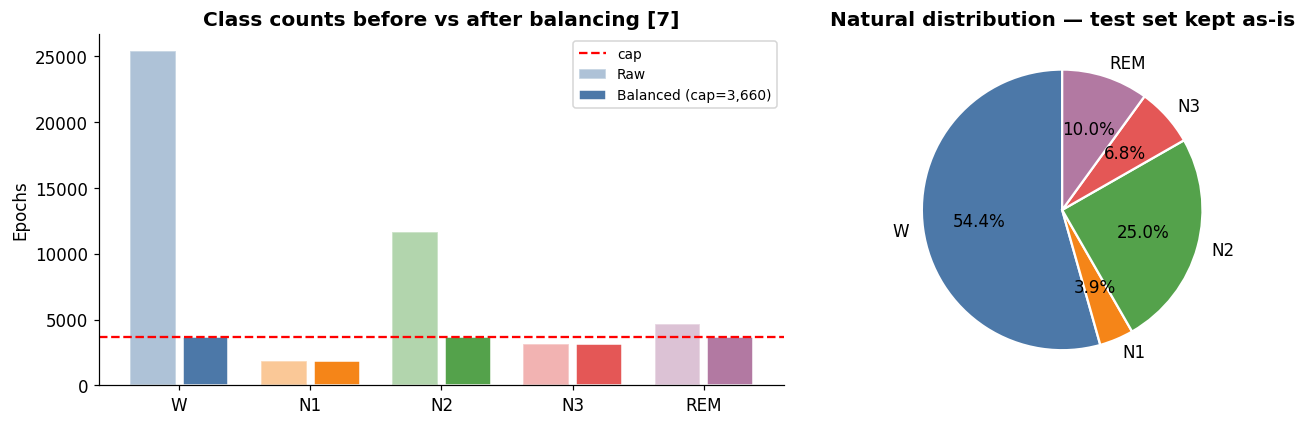

In [21]:
all_y   = np.concatenate([r['y'] for r in rows])
raw_cnt = np.bincount(all_y, minlength=N_STAGES)
cap     = int(raw_cnt.min() * CAP_RATIO)
bal_cnt = np.minimum(raw_cnt, cap)

print('Class distribution (all 25 subjects):')
for i, s in enumerate(STAGE_NAMES):
    bar = '#' * int(raw_cnt[i]/200)
    print(f'  {s:>4}: {raw_cnt[i]:6d} ({raw_cnt[i]/len(all_y)*100:4.1f}%)  {bar}')
print(f'  total : {len(all_y):,}')
print(f'  max/min ratio: {raw_cnt.max()/raw_cnt.min():.1f}x')
print(f'  cap after balancing: {cap:,}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(N_STAGES)
axes[0].bar(x-0.2, raw_cnt, 0.35, label='Raw',
            color=[STAGE_COLORS[s] for s in STAGE_NAMES], alpha=0.45, edgecolor='white')
axes[0].bar(x+0.2, bal_cnt, 0.35, label=f'Balanced (cap={cap:,})',
            color=[STAGE_COLORS[s] for s in STAGE_NAMES], edgecolor='white')
axes[0].axhline(cap, color='red', ls='--', lw=1.5, label='cap')
axes[0].set_xticks(x); axes[0].set_xticklabels(STAGE_NAMES)
axes[0].set_title('Class counts before vs after balancing [7]', fontweight='bold')
axes[0].set_ylabel('Epochs'); axes[0].legend(fontsize=9)
axes[1].pie(raw_cnt, labels=STAGE_NAMES,
            colors=[STAGE_COLORS[s] for s in STAGE_NAMES],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':1.5})
axes[1].set_title('Natural distribution — test set kept as-is', fontweight='bold')
plt.tight_layout()
plt.savefig('fig1_imbalance.png', bbox_inches='tight'); plt.show()

## §3 — Scalar Random Variable vs Random Vector

### Scalar random variable
Each Welch band-power coefficient from one channel is a scalar r.v. conditioned on the hidden stage:
$$X_{\delta}^{(t)} \sim p_{\delta}(\cdot \mid s_t), \quad s_t \in \{W, N1, N2, N3, REM\}$$

### 126-dim random vector
Concatenating 21 features from all 6 channels gives one observation per epoch:
$$\mathbf{X}_t = \bigl(X_1^{(t)},\ldots,X_{126}^{(t)}\bigr)^\top \in \mathbb{R}^{126}$$

The Gaussian HMM emission model:
$$p(\mathbf{X}_t \mid z_t=k) = \mathcal{N}\!\left(\mathbf{X}_t;\,\boldsymbol{\mu}_k,\,\boldsymbol{\Sigma}_k\right)$$

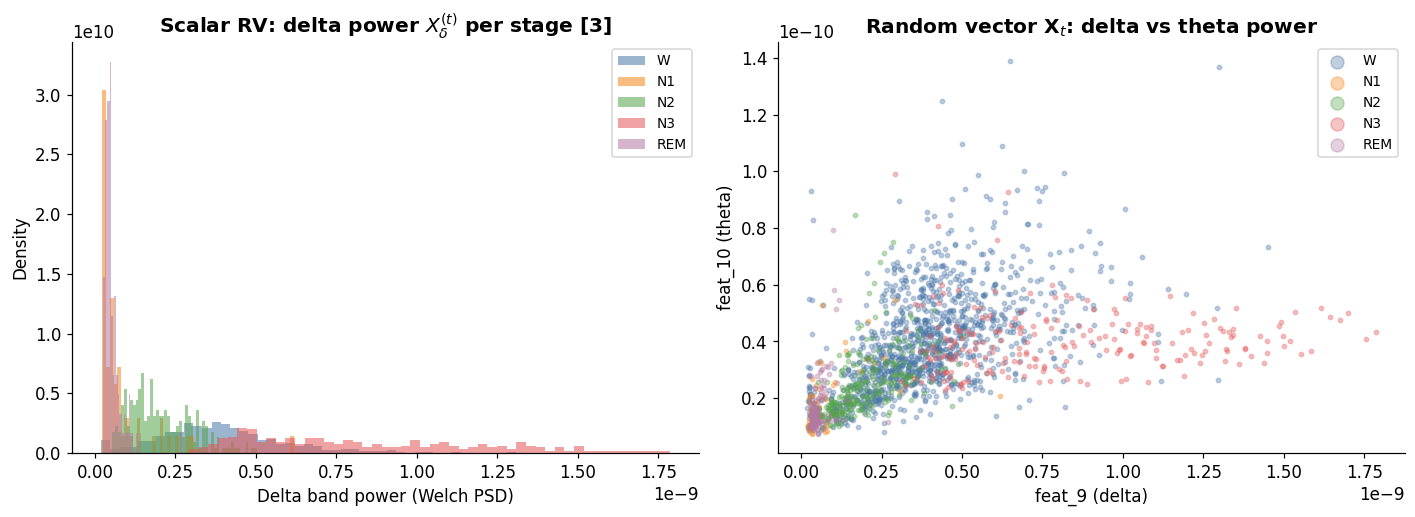

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, s in enumerate(STAGE_NAMES):
    vals = r0['X'][r0['y']==i, 9]
    if len(vals):
        axes[0].hist(vals, bins=50, alpha=0.55, density=True,
                     label=s, color=list(STAGE_COLORS.values())[i])
axes[0].set_title(r'Scalar RV: delta power $X_{\delta}^{(t)}$ per stage [3]',
                   fontweight='bold')
axes[0].set_xlabel('Delta band power (Welch PSD)')
axes[0].set_ylabel('Density'); axes[0].legend(fontsize=9)
idx = np.random.choice(len(r0['y']), min(2000, len(r0['y'])), replace=False)
for i, s in enumerate(STAGE_NAMES):
    m = r0['y'][idx] == i
    if m.sum():
        axes[1].scatter(r0['X'][idx[m],9], r0['X'][idx[m],10],
                        alpha=0.35, s=8, label=s,
                        color=list(STAGE_COLORS.values())[i])
axes[1].set_title(r'Random vector $\mathbf{X}_t$: delta vs theta power',
                   fontweight='bold')
axes[1].set_xlabel('feat_9 (delta)'); axes[1].set_ylabel('feat_10 (theta)')
axes[1].legend(fontsize=9, markerscale=3)
plt.tight_layout()
plt.savefig('fig2_rv.png', bbox_inches='tight'); plt.show()

## §4 — PCA: 126-dim → 30-dim [4]

$$W^* = \arg\max_{W^\top W\,=\,I_k}\; \operatorname{tr}\!\bigl(W^\top \boldsymbol{\Sigma}_X W\bigr)$$

Solution: top-$k$ eigenvectors of $\hat{\boldsymbol{\Sigma}}_X$. We choose $k=30$ (≈92% variance).
$$\mathbf{Z}_t = W^\top\bigl(\mathbf{X}_t - \hat{\boldsymbol{\mu}}\bigr) \in \mathbb{R}^{30}$$

In [23]:
print('Building balanced train/test split + PCA...')
(X_tr, X_te, y_tr, y_te,
 tr_lens, te_lens, scaler, pca,
 train_subj, test_subj,
 class_w) = build_train_test(rows, n_test_subj=5, cap_ratio=2.0, n_pca=30)
print(f'Train subjects: {train_subj}')
print(f'Test  subjects: {test_subj}')

Building balanced train/test split + PCA...

Train distribution BEFORE balancing:
     W:  20298  ( 54.2%)
    N1:   1240  (  3.3%)
    N2:   9200  ( 24.5%)
    N3:   2981  (  8.0%)
   REM:   3756  ( 10.0%)

Train distribution AFTER balancing (cap_ratio=2.0):
     W:   2480  ( 22.2%)
    N1:   1240  ( 11.1%)
    N2:   2480  ( 22.2%)
    N3:   2480  ( 22.2%)
   REM:   2480  ( 22.2%)
  total: 11,160  (was 37,475)

Class weights  w_i = N / (K · N_i):
     W: 0.900
    N1: 1.800
    N2: 0.900
    N3: 0.900
   REM: 0.900

PCA: 30 components → 91.9% variance retained
Train: 11,160   Test: 9,213   dim: 30
Train subjects: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Test  subjects: [20, 21, 22, 23, 24]


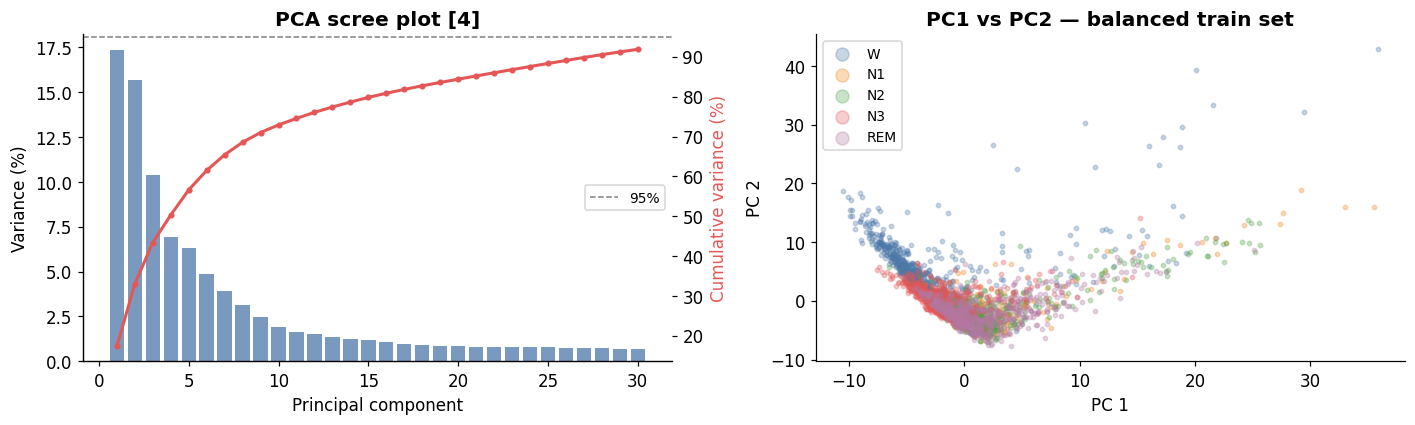

d=30 explains 91.9% variance


In [24]:
ev = pca.explained_variance_ratio_; cumev = np.cumsum(ev)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1,len(ev)+1), ev*100, color='#4c78a8', alpha=0.75, width=0.8)
ax2 = axes[0].twinx()
ax2.plot(range(1,len(ev)+1), cumev*100, 'o-', color='#e45756', lw=2, ms=3)
ax2.axhline(95, color='gray', ls='--', lw=1, label='95%')
ax2.set_ylabel('Cumulative variance (%)', color='#e45756')
ax2.legend(loc='center right', fontsize=9)
axes[0].set_title('PCA scree plot [4]', fontweight='bold')
axes[0].set_xlabel('Principal component'); axes[0].set_ylabel('Variance (%)')
sidx = np.random.choice(len(y_tr), min(3000,len(y_tr)), replace=False)
for i, s in enumerate(STAGE_NAMES):
    m = y_tr[sidx] == i
    if m.sum():
        axes[1].scatter(X_tr[sidx[m],0], X_tr[sidx[m],1],
                        alpha=0.3, s=8, label=s,
                        color=list(STAGE_COLORS.values())[i])
axes[1].set_title('PC1 vs PC2 — balanced train set', fontweight='bold')
axes[1].set_xlabel('PC 1'); axes[1].set_ylabel('PC 2')
axes[1].legend(fontsize=9, markerscale=3)
plt.tight_layout()
plt.savefig('fig3_pca.png', bbox_inches='tight'); plt.show()
print(f'd=30 explains {cumev[29]*100:.1f}% variance')

## §5 — Evaluation Metrics for Imbalanced Data

**Accuracy** alone is misleading — predicting only W+N2 gives ≈79% accuracy.

**Macro-F1** averages per-class F1 with equal weight:
$$F1_{\text{macro}} = \frac{1}{5}\sum_{c=1}^{5}\frac{2\,P_c\,R_c}{P_c + R_c}$$

**Cohen kappa** — AASM standard [2]:
$$\kappa = \frac{P_{\text{obs}} - P_{\text{chance}}}{1 - P_{\text{chance}}}$$

$\kappa < 0.4$ poor · $0.4$–$0.6$ moderate · $>0.6$ good · $>0.8$ excellent.

## §6 — Discrete-Time Markov Chain (DTMC)

Sleep staging satisfies the **Markov property** [5, 6]:
$$P(S_{t+1}=j \mid S_t=i,\, S_{t-1},\ldots) = T_{ij}$$

### Key point: T must be estimated from the original temporal sequences

The balancing step shuffles epochs randomly to break class bias. If we estimated $\hat{T}$ from the shuffled sequence, every transition would be nearly uniform (all rows ≈ [0.22, 0.11, 0.22, 0.22, 0.22]) because the real temporal structure (stages persist for minutes) is destroyed. We therefore concatenate the **original per-subject sequences** in temporal order from the train subjects before fitting $\hat{T}$.

### Laplace-smoothed MLE [5]

$$\hat{T}_{ij} = \frac{n_{ij}+\alpha}{\displaystyle\sum_{k}(n_{ik}+\alpha)}, \quad \alpha=1$$

### Stationary distribution

$$\boldsymbol{\pi}\hat{T}=\boldsymbol{\pi}, \quad\sum_i\pi_i=1, \quad \pi_i\ge 0$$

In [25]:
def fit_dtmc(y, n=N_STAGES, alpha=1.0):
    C = np.full((n, n), alpha)
    for a, b in zip(y[:-1], y[1:]): C[a, b] += 1
    return C / C.sum(1, keepdims=True)

def steady_state(T):
    vals, vecs = np.linalg.eig(T.T)
    pi = np.real(vecs[:, np.argmin(np.abs(vals - 1.))])
    return pi / pi.sum()

# ── Fit T from ORIGINAL ordered sequences (not shuffled balanced data) ──
# Concatenate per-subject label sequences from training subjects in temporal order.
# This preserves the real sleep dynamics (stages persist for minutes),
# giving a meaningful transition matrix instead of a near-uniform one.
y_tr_ordered = np.concatenate(
    [r['y'] for r in rows if r['subject'] in train_subj]
)
T  = fit_dtmc(y_tr_ordered)
pi = steady_state(T)

print('Transition matrix T-hat (rows = current, cols = next):')
print(pd.DataFrame(T, index=STAGE_NAMES,
                   columns=STAGE_NAMES).round(4).to_string())

# Evaluate greedy next-step prediction on the test set
mc_pred = np.array([np.argmax(T[s]) for s in y_te[:-1]])
print()
print_metrics(y_te[1:], mc_pred, label='DTMC next-step')
print('\nStationary distribution pi:')
for i, s in enumerate(STAGE_NAMES):
    print(f'  pi({s}) = {pi[i]:.4f}')

Transition matrix T-hat (rows = current, cols = next):
          W      N1      N2      N3     REM
W    0.9869  0.0104  0.0012  0.0002  0.0012
N1   0.0651  0.6466  0.2554  0.0024  0.0305
N2   0.0117  0.0161  0.9098  0.0498  0.0126
N3   0.0084  0.0057  0.1410  0.8436  0.0013
REM  0.0136  0.0168  0.0178  0.0003  0.9516

[DTMC next-step]  Acc=0.9452  Macro-F1=0.8297  Kappa=0.9101

Stationary distribution pi:
  pi(W) = 0.5414
  pi(N1) = 0.0332
  pi(N2) = 0.2455
  pi(N3) = 0.0796
  pi(REM) = 0.1003


## §7 — Continuous-Time Markov Chain (CTMC) [5]

The DTMC epoch length $\Delta t = 30\,$s is a modelling artefact. A CTMC lifts the process to continuous time via the **generator matrix** $Q$:
$$Q = \frac{1}{\Delta t}\,\operatorname{Re}\!\left[\log\hat{T}\right]$$

We take the real part because `scipy.linalg.logm` can return complex values for matrices with near-zero eigenvalues; the imaginary parts are numerical artefacts and are discarded.

Diagonal entries are set so rows sum to zero: $q_{ii}=-\sum_{j\ne i}q_{ij}$.

**Kolmogorov forward equation:**
$$\mathbf{p}(t) = \mathbf{p}(0)\,e^{Qt}$$

**Mean holding time** (exponential sojourn):
$$\mathbb{E}[H_i] = -\frac{1}{q_{ii}}$$

Rate matrix Q (x1000 for readability):
         W      N1      N2     N3    REM
W   -0.453   0.433  -0.023  0.010  0.034
N1   2.623 -14.698  11.092 -0.230  1.212
N2   0.379   0.684  -3.405  1.902  0.440
N3   0.267   0.195   5.353 -5.825  0.010
REM  0.439   0.699   0.536 -0.005 -1.669

Mean holding times:
  W: 36.8 min
  N1: 1.1 min
  N2: 4.9 min
  N3: 2.9 min
  REM: 10.0 min


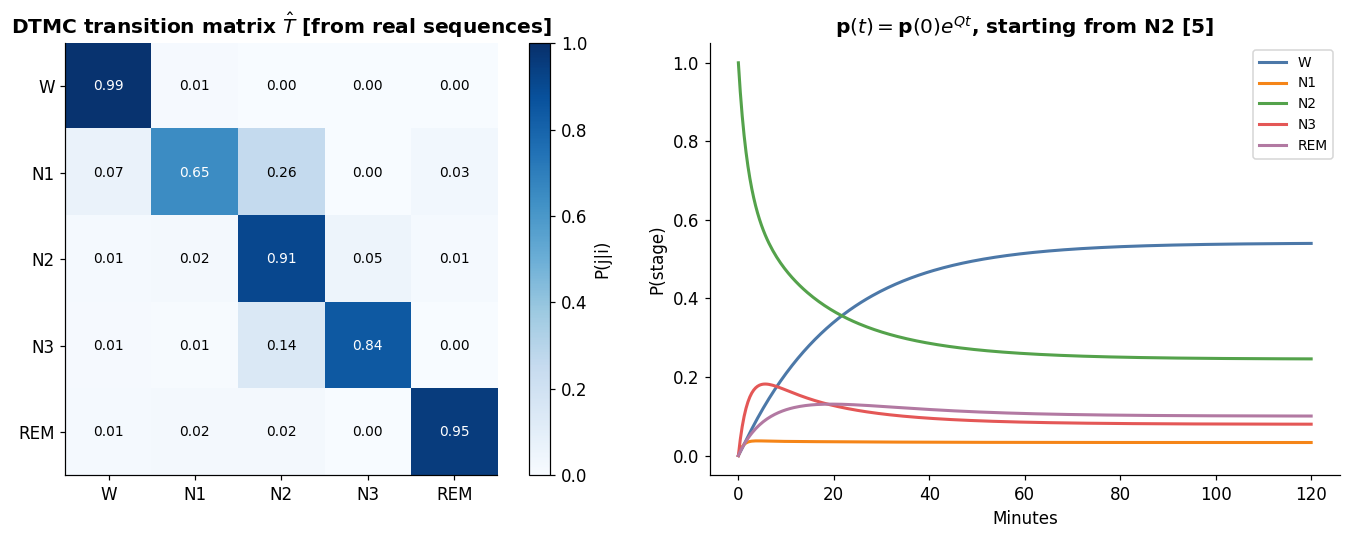

Artefacts saved.
Train: 11,160  Test: 9,213


In [26]:
Q = None
try:
    # Take real part — logm can produce small imaginary artefacts
    Q = np.real(linalg.logm(T)) / 30.
    np.fill_diagonal(Q, 0.)
    np.fill_diagonal(Q, -Q.sum(1))
    print('Rate matrix Q (x1000 for readability):')
    print(pd.DataFrame(Q*1000, index=STAGE_NAMES,
                       columns=STAGE_NAMES).round(3).to_string())
    print('\nMean holding times:')
    for i, s in enumerate(STAGE_NAMES):
        if Q[i,i] < -1e-9:
            print(f'  {s}: {-1./Q[i,i]/60:.1f} min')
except Exception as e:
    print(f'CTMC logm failed: {e}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(T, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(im, ax=axes[0], label='P(j|i)')
axes[0].set_xticks(range(N_STAGES)); axes[0].set_xticklabels(STAGE_NAMES)
axes[0].set_yticks(range(N_STAGES)); axes[0].set_yticklabels(STAGE_NAMES)
axes[0].set_title('DTMC transition matrix $\\hat{T}$ [from real sequences]',
                   fontweight='bold')
for i in range(N_STAGES):
    for j in range(N_STAGES):
        axes[0].text(j, i, f'{T[i,j]:.2f}', ha='center', va='center',
                     fontsize=9, color='white' if T[i,j]>0.55 else 'black')
if Q is not None:
    t_m = np.linspace(0, 120, 300)
    p0  = np.zeros(N_STAGES); p0[2] = 1.   # start in N2
    probs = np.array([p0 @ expm(Q * t * 60) for t in t_m])
    for i, s in enumerate(STAGE_NAMES):
        axes[1].plot(t_m, probs[:,i], label=s,
                     color=list(STAGE_COLORS.values())[i], lw=2)
    axes[1].set_title(
        '$\\mathbf{p}(t)=\\mathbf{p}(0)e^{Qt}$, starting from N2 [5]',
        fontweight='bold')
    axes[1].set_xlabel('Minutes'); axes[1].set_ylabel('P(stage)')
    axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig4_markov.png', bbox_inches='tight'); plt.show()

# ── save artefacts ──
np.save('T.npy', T)              # from real temporal sequences
np.save('X_tr.npy', X_tr);  np.save('X_te.npy', X_te)
np.save('y_tr.npy', y_tr);  np.save('y_te.npy', y_te)
np.save('tr_lens.npy', tr_lens); np.save('te_lens.npy', te_lens)
np.save('class_w.npy', class_w)
print('Artefacts saved.')
print(f'Train: {len(y_tr):,}  Test: {len(y_te):,}')